# Bank Marketing Campaign Analysis
- This project uses bank marketing campaign data to estimate call duration, predict whether a contacted customer will subscribe to a term deposit, and identify customer groups with similar characteristics.

# 1. Setup & Acquisition

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Importing dataset

df = pd.read_csv(r"C:\Users\Dell_PC\Desktop\Fall Semester\Machine Learning\Project\ML-Capstone-Project-yehia\data\bank.csv")

display(df.head())
df.info()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 1.4 MB


# 2. Exploratory Data Analysis & Preprocessing

In [3]:
# Analyzing duplicate rows, missing and unkown values

data = pd.DataFrame({
    'missing': df.isna().sum(),
    'unknown': df.eq('unknown').sum()
})

display(data.loc[data.sum(axis=1) > 0])
print('Duplicate rows:', df.duplicated().sum())

,missing,unknown
job,0,70
education,0,497
contact,0,2346
poutcome,0,8326


Duplicate rows: 0


In [4]:
# Inspecting Classification target column

print(df['deposit'].value_counts())
print(df['deposit'].value_counts(normalize=True) * 100)

deposit
no     5873
yes    5289
Name: count, dtype: int64
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64


    From that inspection we conclude that if a model guessed no for every customer, it would already get 52.6% accuracy. That gives us a baseline to compare my model against later.

In [5]:
# Regression target column

df['duration'].describe()


count    11162.000000
mean       371.993818
std        347.128386
min          2.000000
25%        138.000000
50%        255.000000
75%        496.000000
max       3881.000000
Name: duration, dtype: float64

Text(0, 0.5, 'Number of calls')

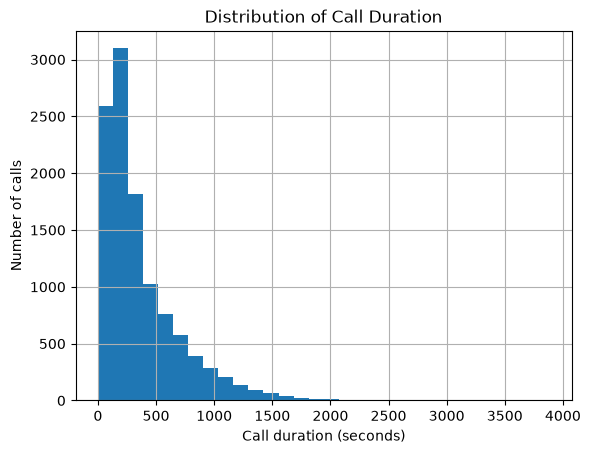

In [6]:
ax = df['duration'].hist(bins=30)
ax.set_title('Distribution of Call Duration')
ax.set_xlabel('Call duration (seconds)')
ax.set_ylabel('Number of calls')

### Call duration is right-skewed. Half of the calls lasted 255 seconds or less, while a few much longer calls pulled the mean up to 372 seconds. Therefore the median gives a better sense of a typical call length.

# 3. Classification - Predicting Term Deposit Subscription

In [7]:
# Splitting data into Features (X) and Target (y)

X = df.drop(columns=['deposit', 'duration'])
y = df['deposit']

print(X.shape)
print(y.shape)

(11162, 15)
(11162,)


In [8]:
# Splitting data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


### Classification Validation Strategy:
    Using 5-fold stratified cross-validation to compare Logistic Regression and Decision Tree. We select the model with the highest average F1 score for the “yes” class and reserve the test set for final evaluation.

In [9]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


### Preprocessing Within Each Fold

In [10]:
# Defining numerical and caregorical features

numeric_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

print('Numerical:', numeric_cols)
print('Categorical:', categorical_cols)

Numerical: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [11]:
# Encoding categorical features and Scaling numeric features

from sklearn.preprocessing import OneHotEncoder, StandardScaler

def prepare_features(X_train, X_val):
    encoder = OneHotEncoder(handle_unknown="ignore")
    scaler = StandardScaler()

    X_train_encoded = encoder.fit_transform(X_train[categorical_cols])
    X_val_encoded = encoder.transform(X_val[categorical_cols])
    encoded_cols = encoder.get_feature_names_out(categorical_cols)

    X_train_scaled = scaler.fit_transform(X_train[numeric_cols])
    X_val_scaled = scaler.transform(X_val[numeric_cols])

    X_train_processed = pd.concat([
        pd.DataFrame(X_train_scaled, index=X_train.index, columns=numeric_cols),
        pd.DataFrame(X_train_encoded.toarray(), index=X_train.index, columns=encoded_cols)
    ], axis=1)

    X_val_processed = pd.concat([
        pd.DataFrame(X_val_scaled, index=X_val.index, columns=numeric_cols),
        pd.DataFrame(X_val_encoded.toarray(), index=X_val.index, columns=encoded_cols)
    ], axis=1)

    return X_train_processed, X_val_processed

## Baseline Logistic Regression vs. Baseline Decision Tree Classifier

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

fold_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train = X_train.iloc[train_idx]
    X_val = X_train.iloc[val_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    X_train_processed, X_val_processed = prepare_features(X_fold_train, X_val)

    scores = {}
    for name, model in models.items():
        model.fit(X_train_processed, y_fold_train)
        predictions = model.predict(X_val_processed)
        scores[name] = f1_score(y_val, predictions, pos_label='yes')

    fold_scores.append(scores)

results = pd.DataFrame(fold_scores, index=range(1, 6))
results.index.name = 'Fold'
results.loc['Mean F1'] = results.mean()
display(results.round(3))

,Logistic Regression,Decision Tree
Fold,,
1,0.634,0.628
2,0.680,0.615
3,0.640,0.614
4,0.646,0.632
5,0.649,0.622
Mean F1,0.650,0.622


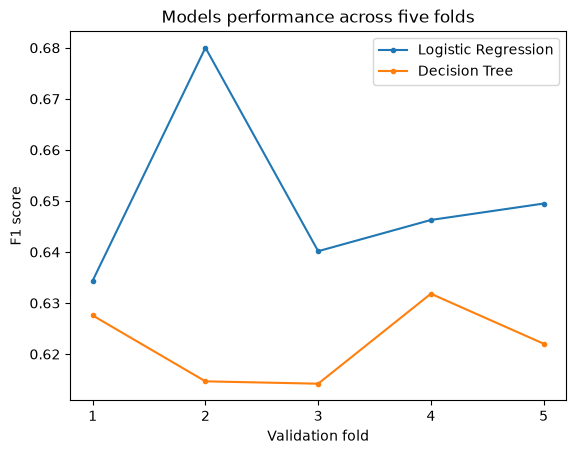

In [13]:
fold_results = results.drop(index="Mean F1")
fold_results.index = fold_results.index.astype(int)

ax = fold_results.plot(
    marker=".",
    xticks=fold_results.index,
    xlabel="Validation fold",
    ylabel="F1 score",
    title="Models performance across five folds"
)

## Tuned Logistic Regression vs. Tuned Decision Tree Classifier

In [14]:
# Tuned Logistic Regression

C_values = [0.01, 0.1, 1, 10]
tuning_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train, X_val = prepare_features(
        X_train.iloc[train_idx], X_train.iloc[val_idx]
    )
    y_fold_train = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    for C in C_values:
        log_model = LogisticRegression(C=C, max_iter=1000)
        log_model.fit(X_fold_train, y_fold_train)
        predictions = log_model.predict(X_val)
        score = f1_score(y_val, predictions, pos_label="yes")
        tuning_scores.append({"C": C, "F1": score})

log_results = pd.DataFrame(tuning_scores).groupby("C")["F1"].mean()
log_results = log_results.sort_values(ascending=False)
best_C = log_results.idxmax()

display(log_results.rename("Mean F1").round(4).to_frame())

,Mean F1
C,
0.01,0.6680
0.10,0.6576
1.00,0.6501
10.00,0.6493


In [15]:
# Tuned Decision Tree

depths = [3, 5, 10, None]
tree_scores = []

for train_idx, val_idx in cv.split(X_train, y_train):
    X_fold_train, X_val = prepare_features(
        X_train.iloc[train_idx], X_train.iloc[val_idx]
    )
    y_fold_train = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    fold_scores_by_depth = {}
    for depth in depths:
        tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
        tree.fit(X_fold_train, y_fold_train)
        predictions = tree.predict(X_val)
        fold_scores_by_depth[depth] = f1_score(y_val, predictions, pos_label="yes")

    tree_scores.append(fold_scores_by_depth)

mean_f1 = {
    depth: sum(fold[depth] for fold in tree_scores) / len(tree_scores)
    for depth in depths
}
best_depth = max(depths, key=mean_f1.get)

tree_results = pd.DataFrame({
    "Max depth": ["Unlimited" if depth is None else str(depth) for depth in depths],
    "Mean F1": [mean_f1[depth] for depth in depths]
}).sort_values("Mean F1", ascending=False)

display(tree_results.set_index("Max depth").round(4))

,Mean F1
Max depth,
Unlimited,0.6221
3,0.6151
10,0.6115
5,0.5929


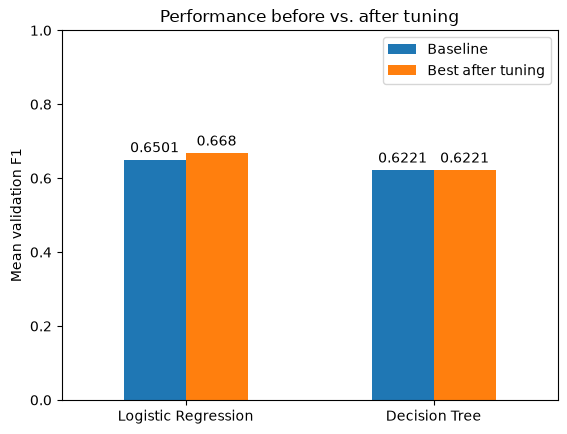

In [16]:
comparison = pd.DataFrame({
    "Baseline": [round(log_results.loc[1], 4), round(mean_f1[None], 4)],
    "Best after tuning": [round(log_results.loc[best_C], 4), round(mean_f1[best_depth], 4)]
}, index=["Logistic Regression", "Decision Tree"])

ax = comparison.plot.bar(
    rot=0,
    ylim=(0, 1),
    ylabel="Mean validation F1",
    title="Performance before vs. after tuning"
)

for bars in ax.containers:
    ax.bar_label(bars, padding=3)

## Conclusion
    - Across five validation folds, reducing C from 1 to 0.01 improved Logistic Regression’s mean F1 score. The unrestricted Decision Tree scored 0.6221, and every depth limit we tested produced a lower score. We selected Logistic Regression with C = 0.01 for final evaluation as it achieved the highest mean validation F1.

In [17]:
# Fitting Logisitic Regression model

X_train_processed, X_test_processed = prepare_features(X_train, X_test)

model = LogisticRegression(C=best_C, max_iter=1000)
model.fit(X_train_processed, y_train)
y_pred = model.predict(X_test_processed)

### Model Evaluation

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label='yes')
recall = recall_score(y_test, y_pred, pos_label='yes')
f1 = f1_score(y_test, y_pred, pos_label='yes')
cm = confusion_matrix(y_test, y_pred, labels=['no', 'yes'])

print('Model Accuracy', round(accuracy, 3))
print('Precision: ', round(precision, 3))
print('Recall: ', round(recall, 3))
print('F1 Score:', round(f1, 3))
print('Confusion Matrix: ')
cm

Model Accuracy 0.695
Precision:  0.712
Recall:  0.6
F1 Score: 0.651
Confusion Matrix: 


array([[918, 257],
       [423, 635]])

# Classification - Final Conclusion
We selected Logistic Regression with C = 0.01 based on five-fold cross-validation. On the 2,233 test customers, it correctly identified 635 of 1,058 subscribers and missed 423. It incorrectly flagged 257 non-subscribers. Compared with the default model, tuning increased recall from 56.2% to 60.0% while reducing precision from 73.3% to 71.2%. Test F1 improved from 0.636 to 0.651, showing a better balance between finding subscribers and keeping predictions accurate.

# 4. Regression - Predicting Call Duration